# Static stickman visualizer

In [1]:
import sys
if '../' not in sys.path:
    sys.path.append('../')

In [2]:
from hmp_utils.motion.body_model_data import SMPL_KEYPOINTS, SMPL_OFFSETS, SMPL_PARENTS, SMPLH_JOINT_NAMES
from hmp_utils.motion.mocap_processor import load_mocap
from hmp_utils.motion.kinematics import ForwardKinematics
from hmp_utils.visualize.static_3d_plot import plot_body_keypoints, interactive_plot_body_keypoints

### Visualize body skeleton

#### Example mocap

For convenience, an example mocap sequence from AMASS is loaded. But in general, any keypoint positional data can be visualized.

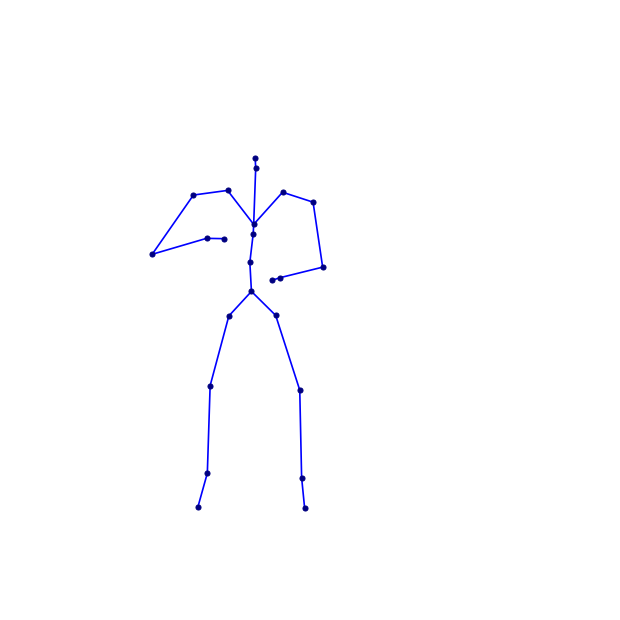

In [3]:
filepath = './example_mocaps/amass_sample.npz'
frame_to_plot = 0

# -- load mocap --
motion = load_mocap(filepath, SMPL_KEYPOINTS)
assert motion is not None

# -- compute joint positions --
kine = ForwardKinematics(SMPL_OFFSETS['neutral'], SMPL_PARENTS)
keypoints_positions = kine.compute_fk(motion.rots, apply_root_rotation=True)
keypoints_positions = keypoints_positions[frame_to_plot]
# -- plot --
plot_body_keypoints(keypoints_positions, SMPL_PARENTS, azimuth=0, show_keypoint_id=False)

#### AMASS Offsets

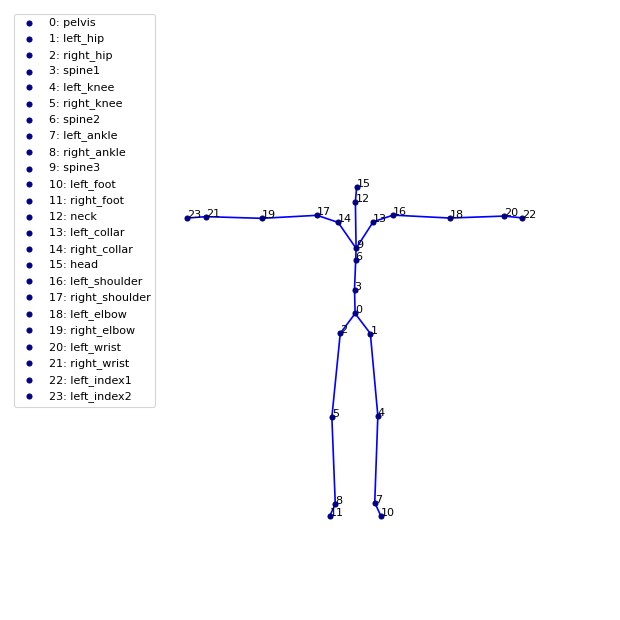

In [4]:
plot_body_keypoints(SMPL_OFFSETS['neutral'], SMPL_PARENTS, azimuth=-90, elevation=90, 
                    keypoint_names=SMPLH_JOINT_NAMES, show_grid=False)

#### Plot only keypoints

If no parents are specified, the body links are not plotted, thus showing only keypoint positions.

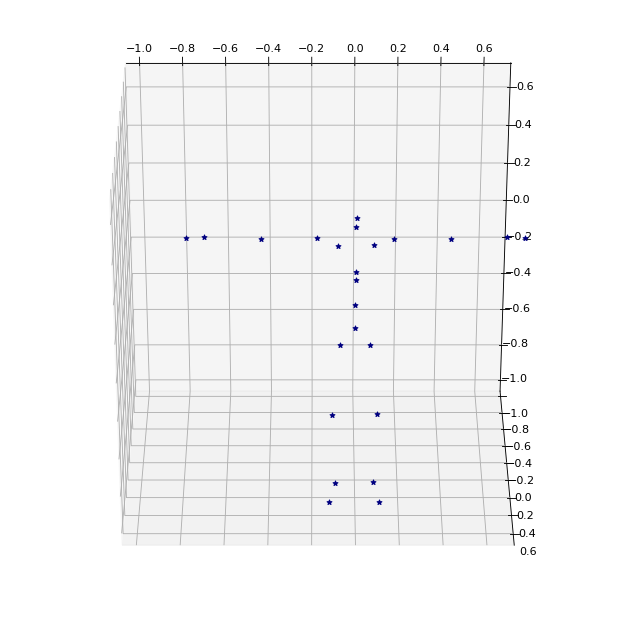

In [5]:
plot_body_keypoints(SMPL_OFFSETS['neutral'], azimuth=-90, elevation=120, 
                    show_grid=True, show_keypoint_id=False, keypoint_marker='*')

### Interactive

In [6]:
interactive_plot_body_keypoints(keypoints_positions, SMPL_PARENTS)

interactive(children=(FloatSlider(value=20.0, description='Elevation', max=90.0, min=-90.0), FloatSlider(value…

### Other examples

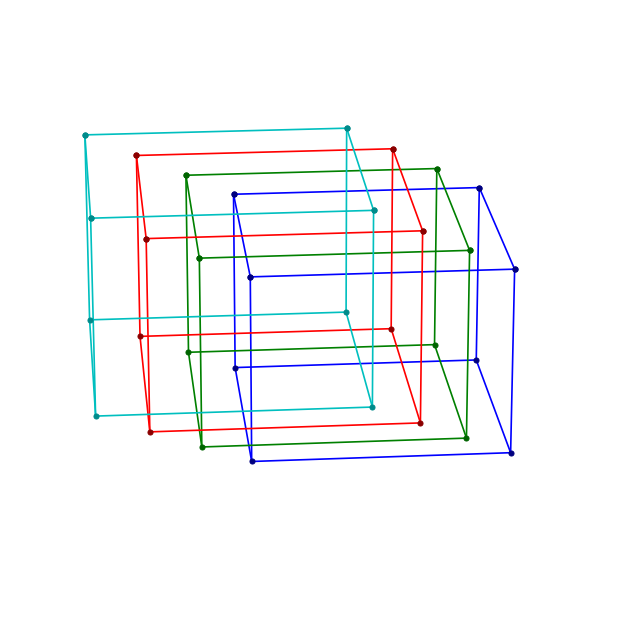

In [7]:
import numpy as np

cube_positions = [[0, 0, 0], [1, 0, 0], [1, 1, 0],
                  [0, 1, 0], [0, 0, 1], [1, 0, 1], 
                  [1, 1, 1], [0, 1, 1], [0, 1, 1],
                  [0, 0, 1], [1, 0, 1], [1, 1, 1]]
cube_parents = [1,2,3,0,5,6,7,4,3,0,1,2]

num_indipendent_bodies = 4
cube_positions = [(np.array(cube_positions)+0.2*i).tolist() for i in range(num_indipendent_bodies)]
cube_parents = [cube_parents for _ in range(num_indipendent_bodies)]

plot_body_keypoints(cube_positions, cube_parents, fig_opts=None, show_keypoint_id=False,
                    keypoint_marker='o', azimuth=85, num_independent_bodies=num_indipendent_bodies,
                    show_grid=False)

In [5]:
import numpy as np

cube_positions = [[0, 0, 0], [1, 0, 0], [1, 1, 0],
                  [0, 1, 0], [0, 0, 1], [1, 0, 1], 
                  [1, 1, 1], [0, 1, 1], [0, 1, 1],
                  [0, 0, 1], [1, 0, 1], [1, 1, 1]]
cube_parents = [1,2,3,0,5,6,7,4,3,0,1,2]

num_cubes = 2
cube_positions = [(np.array(cube_positions)+0.2*i).tolist() for i in range(num_cubes)]
cube_parents = [cube_parents for _ in range(num_cubes)]

bodies = [*cube_positions, SMPL_OFFSETS['neutral']]
parents = [*cube_parents, SMPL_PARENTS]

interactive_plot_body_keypoints(bodies, parents, fig_opts=None, 
                                num_independent_bodies=len(bodies))

interactive(children=(FloatSlider(value=20.0, description='Elevation', max=90.0, min=-90.0), FloatSlider(value…